#### Non LLM Based Parallel Workflow

```
                        START
                          |
                          |
    ---------------------------------------------------
    |                     |                           |
    |                     |                           |
strike rate         boundry percentage          balls per boundary
    |                     |                           |
    |                     |                           |
    ---------------------------------------------------
                          |
                          |
                        Summary
                          |
                          |
                         END
```

State: 
        - runs
        - balls
        - 4s
        - 6s
        - strike rate
        - boundry %
        - balls per boundry
        - summary

In [24]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [25]:
# State

class BatsmanState(TypedDict):
    runs: int
    balls: int
    fours: int
    sixes: int

    strike_rate: float
    balls_per_boundry: float
    boundry_percent: float
    summary: str

In [26]:
def calculate_strike_rate(state: BatsmanState):
    
    strike_rate =  (state['runs'] / state['balls'] ) * 100

    # return only the updated state instead of the entire state this is called partial updates
    return {'strike_rate': strike_rate}

In [27]:
def calculate_balls_per_boundry(state: BatsmanState):
    balls_per_boundry = state['balls']/(state['fours'] + state['sixes'])

    return {'balls_per_boundry': balls_per_boundry}

In [28]:
def calculate_boundry_percent(state: BatsmanState):

    boundry_percent = (((state['fours'] * 4) + (state['sixes'] * 6)) / state['runs']) * 100

    return {'boundry_percent': boundry_percent}

In [29]:
def summary(state: BatsmanState):

    summary = f"""

    Strick Rate - {state['strike_rate']} \n
    Balls per boundry - {state['balls_per_boundry']} \n
    Boundry percent - {state['boundry_percent']} \n
"""
    return {'summary': summary}   

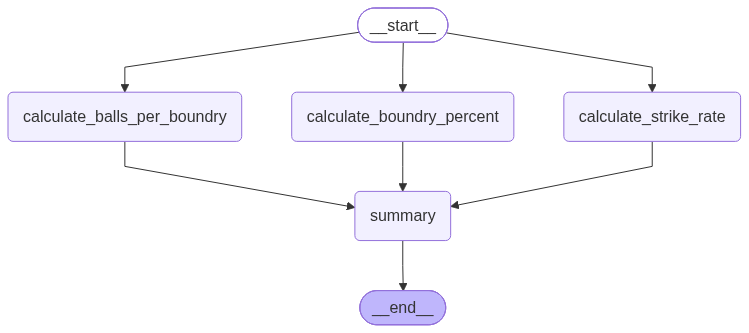

In [30]:
# Create Graph
graph = StateGraph(BatsmanState)

# Nodes
graph.add_node('calculate_strike_rate', calculate_strike_rate)
graph.add_node('calculate_balls_per_boundry', calculate_balls_per_boundry)
graph.add_node('calculate_boundry_percent', calculate_boundry_percent)
graph.add_node('summary', summary)



# edges (parallel workflows)
graph.add_edge(START, 'calculate_strike_rate')
graph.add_edge(START, 'calculate_balls_per_boundry')
graph.add_edge(START, 'calculate_boundry_percent')

graph.add_edge("calculate_strike_rate", "summary")
graph.add_edge("calculate_balls_per_boundry", "summary")
graph.add_edge("calculate_boundry_percent", "summary")

graph.add_edge("summary", END)


workflow = graph.compile()

workflow

In [31]:
initial_state = {
    "runs": 100,
    "balls": 50,
    "fours": 6,
    "sixes": 4
}

final_state = workflow.invoke(initial_state)

final_state

{'runs': 100,
 'balls': 50,
 'fours': 6,
 'sixes': 4,
 'strike_rate': 200.0,
 'balls_per_boundry': 5.0,
 'boundry_percent': 48.0,
 'summary': '\n\n    Strick Rate - 200.0 \n\n    Balls per boundry - 5.0 \n\n    Boundry percent - 48.0 \n\n'}